# Scopus "Six Degrees" Author Graph

We adapt the Six Degrees of Kevin Bacon idea (Blanda, 2013; Hopkins, 2022) to Scopus metadata by turning co-authorship into a graph and using breadth-first search (BFS) to recover the shortest collaboration chain between any two authors. The Kevin Bacon game is fundamentally an unweighted shortest-path problem, so BFS is the right tool for reproducing those "six jumps" dynamics on scholarly data.

## Notebook roadmap

- Peek at the raw Scopus export and automatically detect the title/author columns.
- Normalize author strings (trim, collapse whitespace, title case) and split co-author lists.
- Stream the CSV in chunks, add every co-author pair to an unweighted NetworkX graph, and keep track of papers per edge.
- Compute high-level stats plus a sample shortest path so we can sanity-check the network.
- Persist the graph with joblib and scaffold a Streamlit front-end that loads the artifact without retraining.

In [10]:
import ast
import itertools
import json
import re
from collections import Counter, defaultdict
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from tqdm import tqdm

DATA_PATH = Path("scopus_data_updated.csv")
ARTIFACT_DIR = Path("artifacts")
GRAPH_PATH = ARTIFACT_DIR / "author_graph.joblib"
AUTHOR_NAMES_PATH = ARTIFACT_DIR / "author_names.json"
EMBEDDINGS_PATH = ARTIFACT_DIR / "author_embeddings.npz"
EMBEDDING_INDEX_PATH = ARTIFACT_DIR / "author_embedding_index.joblib"
SUPER_CONNECTOR_MODEL_PATH = ARTIFACT_DIR / "super_connector_model.joblib"
CHUNK_SIZE = 5_000  # tune if you have more memory available
MAX_PAPERS_PER_EDGE = 5  # limit retained paper titles per collaboration
MAX_TITLES_PER_AUTHOR = 25  # limit text corpus per author for embeddings


plt.style.use("seaborn-v0_8")
pd.set_option("display.max_colwidth", 120)


# Helper Functions

In [11]:
def normalize_author(name: str) -> str:
    cleaned = re.sub(r"\s+", " ", str(name).strip())
    return cleaned.title()


def pick_column(columns: list[str], keywords: list[str]) -> str:
    for col in columns:
        normalized = col.lower()
        if all(keyword in normalized for keyword in keywords):
            return col
    return ""


def coerce_sequence(raw: object) -> list:
    if isinstance(raw, (list, tuple, set)):
        return list(raw)
    text = str(raw).strip()
    if not text or text.lower() in {"nan", "none"}:
        return []
    try:
        parsed = ast.literal_eval(text)
    except (ValueError, SyntaxError):
        stripped = text.strip("[]")
        parts = [part.strip() for part in stripped.split(",")]
        return [part.strip("\"'") for part in parts if part.strip("\"'")]
    else:
        if isinstance(parsed, (list, tuple, set)):
            return list(parsed)
        return [parsed]


def parse_author_names_field(raw: object) -> list[str]:
    names = []
    for item in coerce_sequence(raw):
        if isinstance(item, dict):
            value = item.get("$") or item.get("name") or item.get("text")
        else:
            value = str(item)
        value = value.strip().strip("\"'")
        if value:
            names.append(normalize_author(value))
    return names


def parse_author_ids_field(raw: object) -> list[int]:
    auids = []
    for item in coerce_sequence(raw):
        digits = re.sub(r"[^0-9]", "", str(item))
        if digits:
            auids.append(int(digits))
    return auids


def align_names_with_ids(names: list[str], auids: list[int]) -> list[str]:
    if not auids:
        return []
    if not names:
        return [f"AUID {auid}" for auid in auids]
    if len(names) < len(auids):
        filler = [f"AUID {auid}" for auid in auids[len(names) :]]
        names = names + filler
    if len(names) > len(auids):
        names = names[: len(auids)]
    return names

In [12]:
sample_preview = pd.read_csv(DATA_PATH, nrows=5)
available_columns = sample_preview.columns.tolist()

author_names_column = (
    pick_column(available_columns, ["author", "name"]) or pick_column(available_columns, ["authors"])
)
author_id_column = pick_column(available_columns, ["auid"]) or pick_column(
    available_columns, ["author", "id"]
)
title_column = pick_column(available_columns, ["title"])

if not author_names_column or not author_id_column or not title_column:
    raise ValueError(
        "Could not auto-detect the author name, ID, or title columns. "
        "Please update the keyword heuristics to match your file headers."
    )

print("Detected columns:")
print(f"  • author names column: {author_names_column}")
print(f"  • author IDs column  : {author_id_column}")
print(f"  • title column       : {title_column}")
print("\nPreview (first 5 rows):")
display(sample_preview[[title_column, author_names_column, author_id_column]])
print("\nFull column list:")
print(available_columns)

preview_names = sample_preview[author_names_column].astype(str).apply(parse_author_names_field)
preview_ids = sample_preview[author_id_column].astype(str).apply(parse_author_ids_field)
seed_authors = sorted({name for names in preview_names for name in names})[:50]
print(f"\nSampled clean author names ({len(seed_authors)}): {seed_authors}")

Detected columns:
  • author names column: authors_names
  • author IDs column  : authors_auids
  • title column       : title

Preview (first 5 rows):


,title,authors_names,authors_auids
0,Recent developments in bifunctional air electrodes for unitized regenerative proton exchange membrane fuel cells – A...,"['M. M. Hunsom', 'D. D. Kaewsai', 'A. M. A.M. Kannan']","['15071700400', '35362095700', '7006605664']"
1,The benefit of punishment sensitivity on motor performance under pressure,"['Harry H. Manley', 'Stuart S. Beattie', 'Ross R. Roberts', 'Gavin P. G.P. Lawrence', 'Lew L. Hardy']","['55572820600', '36722719500', '24598264300', '7202287838', '7103335493']"
2,MAGIC biomarkers predict long-term outcomes for steroid-resistant acute GVHD,"['Hannah H. Major-Monfried', 'Anne S. A.S. Renteria', 'Attaphol A. Pawarode', 'Pavan P. Reddy', 'Francis F. Ayuk', '...","['55279779900', '55912441800', '6507090238', '7402570277', '6603020536', '7101959075', '35181060700', '35208283600',..."
3,Are endocrine disrupting compounds environmental risk factors for autism spectrum disorder?,"['Amer A. Moosa', 'Henry H. Shu', 'Tewarit T. Sarachana', 'Valerie W. V.W. Hu']","['57196193038', '57202349624', '26640658800', '7003394845']"
4,Probabilistic regular grammar inference algorithm using incremental technique,"['Torsak T. Penpinun', 'Athasit A. Surarerks']","['57204124034', '9334839700']"



Full column list:
['eid', 'title', 'year', 'doi', 'journal', 'abstract', 'language', 'cited_by_count', 'source_id', 'authors_auids', 'authors_names', 'author_affil_names', 'author_affil_countries', 'author_count', 'keywords', 'subject_areas', 'references', 'ref_count', 'year_folder', 'source_file']

Sampled clean author names (49): ['A. M. A.M. Kannan', 'Aaron A. Etra', 'Amer A. Moosa', 'Andrew C. A.C. Harris', 'Anne S. A.S. Renteria', 'Athasit A. Surarerks', 'Attaphol A. Pawarode', 'Carrie L. C.L. Kitko', 'D. D. Kaewsai', 'Daniela D. Weber', 'Elizabeth O. E.O. Hexner', 'Ernst E. Holler', 'Francis F. Ayuk', 'Gavin P. G.P. Lawrence', 'George G. Morales', 'Gregory A. G.A. Yanik', 'Hannah H. Major-Monfried', 'Harry H. Manley', 'Henry H. Shu', 'Ivan I. Torres', 'James L.M. J.L.M. Ferrara', 'Jay J. Shah', 'John E. J.E. Levine', 'Kitsada K. Wudhikarn', 'Lew L. Hardy', 'M. M. Hunsom', 'Matthew J. M.J. Hartwell', 'Matthias M. Wölfl', 'Michael M. Pulsipher', 'Mina M. Aziz', 'Mohammed S. M.S. C

## Build the author graph

The CSV can be much larger than memory, so we stream it in `CHUNK_SIZE` batches, normalize every author list, and add an unweighted edge for each co-author pair. Each edge stores how many times two authors collaborated plus the list of paper titles that justify the link.

In [13]:
author_graph = nx.Graph()
titles_seen: set[str] = set()
auid_to_names: defaultdict[int, set[str]] = defaultdict(set)
name_to_auids: defaultdict[str, set[int]] = defaultdict(set)
unique_author_names: set[str] = set()
author_to_titles: defaultdict[int, list[str]] = defaultdict(list)

reader = pd.read_csv(
    DATA_PATH,
    usecols=[title_column, author_names_column, author_id_column],
    chunksize=CHUNK_SIZE,
 )

for chunk in tqdm(reader, desc="Linking co-authors"):
    chunk = chunk.dropna(subset=[author_id_column])
    chunk["author_ids"] = chunk[author_id_column].apply(parse_author_ids_field)
    chunk["author_names_clean"] = chunk[author_names_column].apply(parse_author_names_field)
    chunk = chunk[chunk["author_ids"].map(len) > 0]
    titles_seen.update(chunk[title_column].astype(str))

    for _, row in chunk.iterrows():
        auids: list[int] = row["author_ids"]
        names: list[str] = align_names_with_ids(row["author_names_clean"], auids)
        if not auids:
            continue

        current_authors: list[int] = []
        for auid, name in zip(auids, names):
            author_graph.add_node(auid)
            auid_to_names[auid].add(name)
            name_to_auids[name].add(auid)
            unique_author_names.add(name)
            current_authors.append(auid)

        title = str(row[title_column]).strip()
        for author_a, author_b in itertools.combinations(current_authors, 2):
            if author_graph.has_edge(author_a, author_b):
                edge_data = author_graph[author_a][author_b]
                if len(edge_data["papers"]) < MAX_PAPERS_PER_EDGE:
                    edge_data["papers"].add(title)
                edge_data["weight"] += 1
            else:
                author_graph.add_edge(author_a, author_b, papers={title}, weight=1)

        if title:
            for auid in current_authors:
                titles = author_to_titles[auid]
                if len(titles) < MAX_TITLES_PER_AUTHOR and title not in titles:
                    titles.append(title)

Linking co-authors: 0it [00:00, ?it/s]

Linking co-authors: 5it [24:29, 293.88s/it]
Linking co-authors: 5it [24:29, 293.88s/it]


In [14]:
summary = {
    "nodes": author_graph.number_of_nodes(),
    "edges": author_graph.number_of_edges(),
}
if summary["nodes"]:
    summary["avg_degree"] = sum(dict(author_graph.degree()).values()) / summary["nodes"]
else:
    summary["avg_degree"] = 0.0

components = sorted(nx.connected_components(author_graph), key=len, reverse=True)
largest_component = components[0] if components else set()
summary["connected_components"] = len(components)
summary["largest_component_size"] = len(largest_component)
summary["largest_component_share"] = (
    len(largest_component) / summary["nodes"] if summary["nodes"] else 0
)

summary_frame = pd.DataFrame(list(summary.items()), columns=["metric", "value"])
display(summary_frame)

degree_series = pd.Series(dict(author_graph.degree())).sort_values(ascending=False)
top_authors = degree_series.head(15)
display(top_authors.to_frame(name="degree"))

,metric,value
0,nodes,7.425000e+04
1,edges,4.570815e+07
2,avg_degree,1.231196e+03
3,connected_components,6.390000e+02
4,largest_component_size,7.138100e+04
5,largest_component_share,9.613603e-01


,degree
35227095300,13995
15029012100,13760
12758684000,13760
57720737200,13264
57219170016,13211
35227502700,13209
29767622300,13209
12758816400,13209
7101600969,13182
57217455860,13182


In [15]:
def shortest_author_path(graph: nx.Graph, source: int, target: int) -> list[int]:
    """Return the author chain from source to target using BFS."""
    try:
        return nx.shortest_path(graph, source=source, target=target)
    except nx.NodeNotFound as exc:
        raise ValueError(f"Author not found in graph: {exc}") from exc
    except nx.NetworkXNoPath:
        return []


def format_author_label(auid: int) -> str:
    names = sorted(auid_to_names.get(auid, []))
    primary = names[0] if names else f"AUID {auid}"
    return f"{primary} ({auid})"


def path_details(graph: nx.Graph, path: list[int]) -> pd.DataFrame:
    """Summarize each hop with at most three supporting papers."""
    rows = []
    for author_a, author_b in zip(path[:-1], path[1:]):
        papers = graph[author_a][author_b]["papers"]
        paper_list = list(papers)
        rows.append(
            {
                "from": format_author_label(author_a),
                "to": format_author_label(author_b),
                "sample_papers": ", ".join(paper_list[:3]),
                "shared_paper_count": len(papers),
            }
        )
    return pd.DataFrame(rows)


demo_path = None
candidates = top_authors.index.tolist()
for idx, author_a in enumerate(candidates):
    for author_b in candidates[idx + 1 :]:
        try:
            path = shortest_author_path(author_graph, author_a, author_b)
        except ValueError:
            continue
        except nx.NetworkXNoPath:
            continue
        demo_path = (author_a, author_b, path)
        break
    if demo_path:
        break

if demo_path:
    start_author, end_author, path = demo_path
    print(
        f"Shortest path between '{format_author_label(start_author)}' and "
        f"'{format_author_label(end_author)}' has {len(path) - 1} jumps."
    )
    chain_frame = pd.DataFrame({"author_chain": [format_author_label(node) for node in path]})
    display(chain_frame)
    display(path_details(author_graph, path))
else:
    print("Unable to find a demonstrative path among the highest-degree authors.")

Shortest path between 'B. B. Clerbaux (35227095300)' and 'D. D. Lelas (15029012100)' has 1 jumps.


,author_chain
0,B. B. Clerbaux (35227095300)
1,D. D. Lelas (15029012100)


,from,to,sample_papers,shared_paper_count
0,B. B. Clerbaux (35227095300),D. D. Lelas (15029012100),"Search for Leptoquarks Coupled to Third-Generation Quarks in Proton-Proton Collisions at s =13 TeV, Search for Physi...",5


## Fun visualizations

A quick look at degree distribution, component sizes, and the heaviest collaboration edges helps sanity-check the network while adding a bit of flair for presentations.

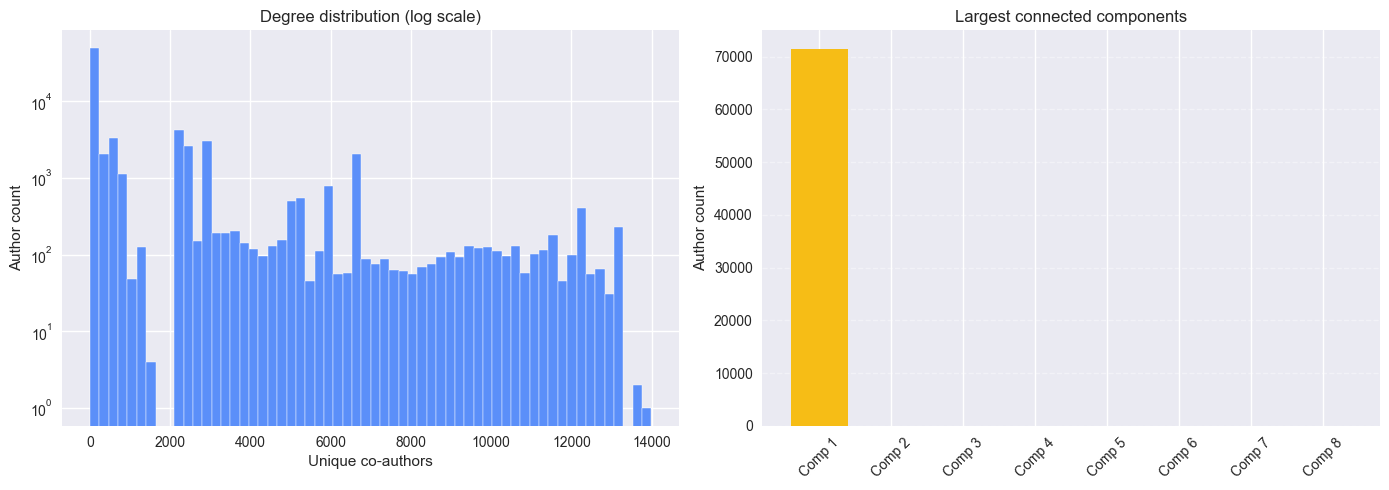

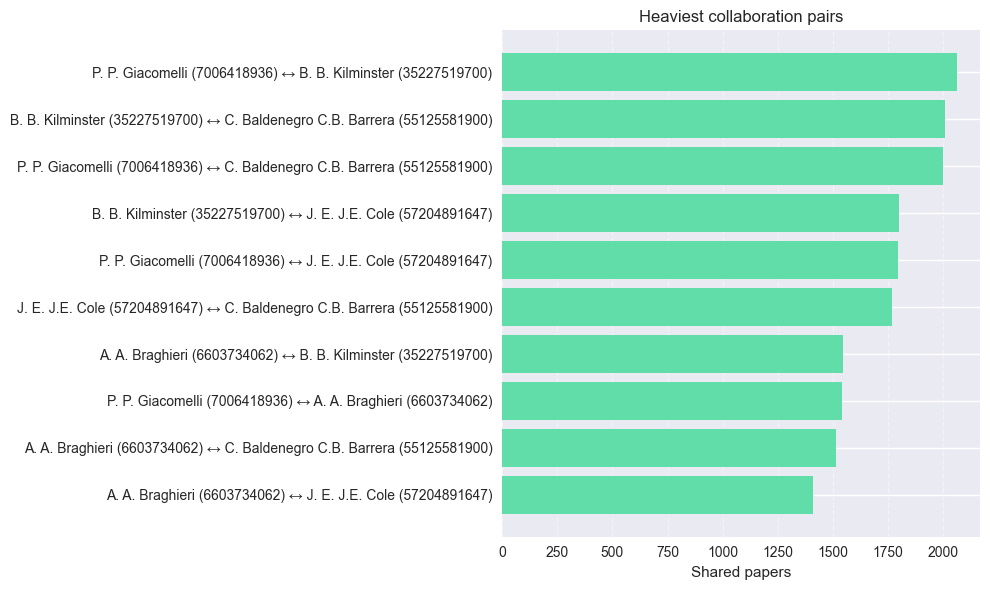

In [16]:
degree_values = pd.Series(dict(author_graph.degree()), name="degree")
component_sizes = pd.Series([len(component) for component in components], name="component_size")
edge_weights = pd.Series(nx.get_edge_attributes(author_graph, "weight"), name="collaborations")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(degree_values, bins=60, color="#5B8FF9", edgecolor="white")
axes[0].set_yscale("log")
axes[0].set_title("Degree distribution (log scale)")
axes[0].set_xlabel("Unique co-authors")
axes[0].set_ylabel("Author count")

top_components = component_sizes.sort_values(ascending=False).head(8)
axes[1].bar(range(len(top_components)), top_components.values, color="#F6BD16")
axes[1].set_xticks(range(len(top_components)))
axes[1].set_xticklabels([f"Comp {idx+1}" for idx in range(len(top_components))], rotation=45)
axes[1].set_title("Largest connected components")
axes[1].set_ylabel("Author count")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

if not edge_weights.empty:
    top_edges = edge_weights.sort_values(ascending=False).head(10)
    edge_labels = [
        f"{format_author_label(a)} ↔ {format_author_label(b)}"
        for a, b in top_edges.index
    ]
    fig2, ax2 = plt.subplots(figsize=(10, 6))
    ax2.barh(edge_labels[::-1], top_edges.values[::-1], color="#61DDAA")
    ax2.set_title("Heaviest collaboration pairs")
    ax2.set_xlabel("Shared papers")
    ax2.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
else:
    print("No edge weights available to visualize.")

## Persist author metadata

We stash the name↔AUID mappings directly on the NetworkX graph and dump a plain JSON list of normalized author names so the Streamlit UI can load them quickly without rebuilding the graph.

In [17]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

auid_to_names_serializable = {
    int(auid): sorted(names)
    for auid, names in auid_to_names.items()
    if names
}
name_to_auids_serializable = {
    normalize_author(name): sorted(ids)
    for name, ids in name_to_auids.items()
    if ids
}

author_graph.graph["auid_to_names"] = auid_to_names_serializable
author_graph.graph["name_to_auids"] = name_to_auids_serializable
author_graph.graph["source_file"] = DATA_PATH.name
author_graph.graph["unique_author_count"] = len(unique_author_names)

AUTHOR_NAMES_PATH.write_text(
    json.dumps(sorted(unique_author_names)),
    encoding="utf-8",
)

print(
    "Persisted metadata: "
    f"{len(auid_to_names_serializable):,} authors with IDs, "
    f"{len(unique_author_names):,} unique normalized names."
)
print(f"Author suggestions saved to {AUTHOR_NAMES_PATH.resolve()}")

Persisted metadata: 74,250 authors with IDs, 73,698 unique normalized names.
Author suggestions saved to D:\Coding\datascience\finalproj\artifacts\author_names.json


## Persist the graph for Streamlit

We save the NetworkX object with joblib so the Streamlit app can load the artifact instantly without rebuilding the graph.

In [18]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
for author_a, author_b, data in author_graph.edges(data=True):
    papers = data.get("papers")
    if isinstance(papers, set):
        data["papers"] = tuple(sorted(papers))
saved_path = joblib.dump(
    author_graph,
    GRAPH_PATH,
    compress=3,
    protocol=4,
 )[0]
print(f"Saved graph to {saved_path}")
print(f"File size: {GRAPH_PATH.stat().st_size / 1_048_576:.2f} MB")

Saved graph to artifacts\author_graph.joblib
File size: 621.96 MB


## AI module: Transformer embeddings and ML models

We enrich each author with a mini language model profile (BERT embeddings of their paper titles) to enable semantic similarity searches, clustering, and a supervised “super-connector” classifier.

In [19]:
import importlib
import subprocess
import sys

packages = ["sentence-transformers", "scikit-learn"]
for package in packages:
    if importlib.util.find_spec(package.split("[")[0]) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

c:\Users\ADMIN\.virtualenvs\datascience-JKuXFAqE\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:
author_documents: list[str] = []
embedding_auids: list[int] = []

for auid in sorted(author_graph.nodes()):
    titles = author_to_titles.get(auid, [])
    doc_parts = titles[:MAX_TITLES_PER_AUTHOR]
    if len(doc_parts) < 3:
        doc_parts.extend(sorted(auid_to_names.get(auid, [])))
    if not doc_parts:
        doc_parts = [f"Scopus author {auid}"]
    author_documents.append(". ".join(doc_parts))
    embedding_auids.append(auid)

print(f"Prepared {len(author_documents):,} author documents for embedding.")

Prepared 74,250 author documents for embedding.


In [21]:
encoder_name = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(encoder_name)

author_embeddings = encoder.encode(
    author_documents,
    batch_size=64,
    convert_to_numpy=True,
    show_progress_bar=True,
)

cluster_k = min(20, max(2, len(embedding_auids) // 2000))
cluster_model = KMeans(n_clusters=cluster_k, random_state=42, n_init="auto")
cluster_labels = cluster_model.fit_predict(author_embeddings)

np.savez_compressed(
    EMBEDDINGS_PATH,
    embeddings=author_embeddings.astype(np.float32),
    auids=np.array(embedding_auids, dtype=np.int64),
    cluster_labels=cluster_labels.astype(np.int16),
)

joblib.dump({"encoder": encoder_name, "cluster_k": int(cluster_k)}, EMBEDDING_INDEX_PATH)
print(
    f"Persisted embeddings to {EMBEDDINGS_PATH} using {encoder_name}. "
    f"Cluster count: {cluster_k}."
)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Batches: 100%|██████████| 1161/1161 [09:41<00:00,  2.00it/s]



Persisted embeddings to artifacts\author_embeddings.npz using sentence-transformers/all-MiniLM-L6-v2. Cluster count: 20.


### Super-connector classifier

Using the embeddings as features, we train a logistic regression model that predicts whether an author sits in the top decile of the degree distribution (i.e., has unusually many co-authors).

In [22]:
degree_targets = pd.Series(dict(author_graph.degree()))
super_threshold = float(degree_targets.quantile(0.9))
target_vector = (degree_targets.reindex(embedding_auids).fillna(0) >= super_threshold).astype(int).values

X_train, X_test, y_train, y_test = train_test_split(
    author_embeddings,
    target_vector,
    test_size=0.2,
    random_state=42,
    stratify=target_vector,
)

classifier = LogisticRegression(
    max_iter=1_000,
    class_weight="balanced",
    solver="lbfgs",
)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
report = classification_report(y_test, y_pred)
print(report)

joblib.dump(
    {
        "model": classifier,
        "threshold": super_threshold,
        "encoder": encoder_name,
        "target_definition": "1 indicates top 10% of the degree distribution",
    },
    SUPER_CONNECTOR_MODEL_PATH,
)
print(f"Saved super-connector model to {SUPER_CONNECTOR_MODEL_PATH}")

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     13365
           1       0.92      1.00      0.96      1485

    accuracy                           0.99     14850
   macro avg       0.96      0.99      0.98     14850
weighted avg       0.99      0.99      0.99     14850

Saved super-connector model to artifacts\super_connector_model.joblib


### Files produced

- `author_embeddings.npz`: raw embeddings, author IDs, and cluster labels.
- `author_embedding_index.joblib`: encoder metadata for reproducibility.
- `super_connector_model.joblib`: logistic regression weights + threshold, ready for Streamlit to score authors.

## Streamlit interface

The app below loads the serialized graph, normalizes user-provided names the same way we did while training, and surfaces the BFS path (plus supporting papers) without recomputing the network.

### Running Streamlit

1. Ensure `author_graph.joblib` exists by executing the notebook cells above.
2. Activate your environment and run `streamlit run streamlit_app.py` from the project root.
3. Type the normalized start/end author names (title case, matching the Scopus spelling) to retrieve the BFS path and the supporting paper list.